# A trellis built backwards

<div class="alert alert-info">

**Summary**

In this lesson the reader binds the stages of one period of the portfolio–consumption model to their parameter values, methods and settings, builds a trellis of six years from nothing, the last year first, draws it as it grows, and finds it equal to the trellis its file writes. The object inspected is the trellis. The lesson constructs the trellis and checks supplied terminal data. The next lesson solves it.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [Two stages, two orders](01-two-stages-two-orders.ipynb): the stages and periods of this model.

**Formal account** — [Periods](../../../docs/Bellman-Sym/06-period.md) and [Trellises](../../../docs/Bellman-Sym/07-trellis.md): the period written once, and the trellis indexed back from its last period.

**Used by** — [Solving the two orders](03-solving-the-two-orders.ipynb): the next lesson, which solves this trellis.

**See also** — [The portfolio–consumption application](../../../applications/cons-port/README.md): the files read here.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| [[trellis]] | A diagram of periods joined by connections, built backwards from the last. |
| inter-period connector | The mapping that joins the fields leaving one period to those at which the next period arrives. |
| [[accretion-modules\|accretion]] | Appending to a trellis the period one earlier in time. |
| stage occurrence | One use of a stage declaration at a position, its address in a period. |
| [[specified_stage\|specified]] | Said of a stage bound to its values, methods and settings. |

</div>

A household consumes out of its resources and divides its savings between a safe asset and a risky one, choosing the risky share before the return and next year's income are drawn; the declaration repeats this stationary problem six times. Trellis positions determine the order of composition. They do not supply an age or change the stage's calibration. An age-dependent model must declare age as a field and supply its terminal value.

| Written | Meaning |
|---|---|
| `trellis["periods"][h]` | period $h$, the period $h$ years before the last; $h = 0$ is the last |
| `trellis["inter_connectors"][h]` | the mapping from the continuation fields that leave period $h + 1$ to the arrival fields of period $h$ |
| `a`, `k` | savings $\mathrm{a}$, which leave a period through the discount stage, and capital $\mathrm{k}$, at which the portfolio stage arrives |
| `m_next`, `m` | the resources $\mathrm{m}'$ the portfolio stage produces, and the resources $\mathrm{m}$ at which consumption arrives |
| `β` | the discount factor $\beta$ |

The lesson reads these files, given by their paths from the repository root:

- `applications/cons-port/declaration/stages/cons/cons.bl`
- `applications/cons-port/declaration/stages/port/port.bl`
- `applications/cons-port/declaration/stages/disc/disc.bl`
- `applications/cons-port/declaration/calibration/portfolio.yml`
- `applications/cons-port/declaration/stages/cons/methods.bl`
- `applications/cons-port/declaration/stages/port/methods.bl`
- `applications/cons-port/declaration/stages/disc/methods.bl`
- `applications/cons-port/declaration/settings/cons_wide.yml`
- `applications/cons-port/declaration/settings/port_wide.yml`
- `applications/cons-port/declaration/spec.port-cons.yml`
- `applications/cons-port/declaration/trellis.port-cons.yml`
- `applications/cons-port/code/cons_port_tool.py`

It writes no file. The first code cell imports the set-up module of the tutorials collection, checkout, which sets the working directory to the repository root and makes the package importable; it defines one function, explore, which opens the interactive view of a stage or a trellis in Google's Model Explorer and which this lesson does not call. The cell then imports the functions the lesson calls, from bellman.stage and bellman.trellis.

In [1]:
import checkout
from bellman.stage import elaborate_stage, load_stage
from bellman.trellis import (
    accrete,
    calibrate_trellis,
    configure_trellis,
    connection_report,
    diagram_trellis,
    elaborate_trellis,
    load_recipe,
    methodize_trellis,
)
import numpy as np
import cons_port_tool as tool


## Stage construction

`elaborate` constructs the symbolic stage. `methodize` selects its numerical methods, `calibrate` binds economic parameters, and `configure` binds numerical settings. These are separate steps. The binding verbs mutate this stage; separate trellis occurrences receive their own stage objects.


In [2]:
symbolic = elaborate_stage(load_stage("applications/cons-port/declaration/stages/cons/cons.bl"))

The next cell selects the endogenous grid method from the methods file.


In [3]:
methodized = symbolic.methodize("applications/cons-port/declaration/stages/cons/methods.bl")


Calibration binds the fixed economic parameters after methodization.


In [4]:
calibrated = methodized.calibrate("applications/cons-port/declaration/calibration/portfolio.yml")


The next cell binds the settings and names the result `cons`, as [lesson 01](01-two-stages-two-orders.ipynb) named the stage.

In [5]:
cons = calibrated.configure("applications/cons-port/declaration/settings/cons_wide.yml")


The four names name one stage, which the verbs bound in place; its short form shows the version it has reached, specified, since all three bindings are bound.

In [6]:
symbolic, calibrated, methodized, cons

(ElaboratedStage('cons', specified),
 ElaboratedStage('cons', specified),
 ElaboratedStage('cons', specified),
 ElaboratedStage('cons', specified))

The next cell lists its methods, one line for each place a typing entry types, with the method word, the grid as the entry writes it and the handler. The endogenous-grid method stands on the policy builder, `policy`, with its grid of savings, whose spacing is the word `!expmult`, multi-exponential and dense near zero, and its handler `cons-port:egm`; the representation `!Linear` stands at `cntn_to_dcsn.evaluate`, the Evaluation that closes the decision builder, where the value and its stated derivative, the envelope line the addition appends, are stored, with its grid of resources.

In [7]:
cons.methods

cntn_to_dcsn.evaluate   !Linear   !Cartesian(m=(m_min, m_max, n_m, !expmult))
policy                  !egm   !Cartesian(a=(a_min, a_max, n_a, !expmult))   "cons-port:egm"

The next cell lists its settings, each with the set the addition declares for it, its value, and the place and the method that read it. The savings grid, `n_a`, `a_min` and `a_max`, is read at `policy` by `!egm`, and the grid of resources, `n_m`, `m_min` and `m_max`, at `cntn_to_dcsn.evaluate` by `!Linear`; the column `grid` gives the kind of each grid, `!Cartesian`. The last two names are valued by the settings file and declared by no entry of the addition, so they are listed with no set and no reader.

In [8]:
cons.settings

name    set  value   read at                by       grid
n_a     ℕ    16000   policy                 !egm     !Cartesian
a_min   Xa   1e-06   policy                 !egm     !Cartesian
a_max   Xa   2000.0  policy                 !egm     !Cartesian
n_m     ℕ    64000   cntn_to_dcsn.evaluate  !Linear  !Cartesian
m_min   Xm   0.01    cntn_to_dcsn.evaluate  !Linear  !Cartesian
m_max   Xm   2000.0  cntn_to_dcsn.evaluate  !Linear  !Cartesian
n_toll       200
n_init       20041

The next cell specifies the portfolio stage by the same three verbs, written as one chain, and names it `port`.

In [9]:
port = (elaborate_stage(load_stage("applications/cons-port/declaration/stages/port/port.bl"))
        .methodize("applications/cons-port/declaration/stages/port/methods.bl")
        .calibrate("applications/cons-port/declaration/calibration/portfolio.yml")
        .configure("applications/cons-port/declaration/settings/port_wide.yml"))


The discount stage's addition declares no setting, so the stage is configured with an empty mapping; the next cell names it `disc`.

In [10]:
disc = (elaborate_stage(load_stage("applications/cons-port/declaration/stages/disc/disc.bl"))
        .methodize("applications/cons-port/declaration/stages/disc/methods.bl")
        .calibrate("applications/cons-port/declaration/calibration/portfolio.yml")
        .configure({}))


Both are specified.

In [11]:
port, disc

(ElaboratedStage('port', specified), ElaboratedStage('disc', specified))

## The empty trellis

The Python representation of a trellis is a dictionary of two lists, `periods` and `inter_connectors`, both empty at the start. The next cell writes it and names it `empty`.

In [12]:
empty = {"periods": [], "inter_connectors": []}

The **horizon** of a trellis is the number of its periods; the empty trellis has none.

In [13]:
len(empty["periods"])

0

## The last period

The last period is appended first: the period of [lesson 01](01-two-stages-two-orders.ipynb) whose returns are drawn at its beginning, in which the connector `{w: m}` connects the portfolio stage's `w` to the resources at which consumption is chosen, and the discount stage's savings `a` leave the period. The next cell writes it and names it `beginning`, as lesson 01 did.

In [14]:
beginning = {"stages": {"port": port, "cons": cons, "disc": disc}, "connectors": [{"w": "m"}]}

`accrete` appends a period to a trellis and returns a new trellis, leaving the one given unchanged. The last period takes no inter-period connector, since no period follows it. The value after it, a function of the savings `a` that leave it, is not part of the trellis: the next lesson supplies it when the trellis is solved. Appending solves nothing; each **stage occurrence**, one use of a stage at one position, keeps its version. The next cell appends the period to the empty trellis and names the result `one_year`.

In [15]:
one_year = accrete(empty, beginning)

It holds one period and no inter-period connector.

In [16]:
len(one_year["periods"]), one_year["inter_connectors"]

(1, [])

`diagram_trellis` draws a trellis, each period in a frame labeled `periods[h]` with its index $h$ and holding one box for each stage, the last period, $h = 0$, at the right; the drawing is stored nowhere.

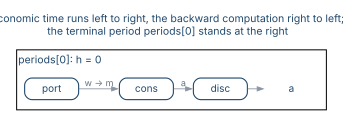

In [17]:
diagram_trellis(one_year)

## The period before it

A trellis grows only backwards: the next period appended is the year before the last, with the inter-period connector `{disc.a: k}`, by which the savings leaving the earlier year are the capital at which the later year's portfolio stage arrives. `accrete` writes it at `inter_connectors[0]` and checks the continuation `a` of its `disc` occurrence and that the period after it arrives at `k`. Both `cons` and `disc` have a continuation field `a`, so `disc.a` selects the discounted savings. The next cell appends the period and names the result `two_years`.

In [18]:
two_years = accrete(one_year, beginning, {"disc.a": "k"})

The connector stands at index 0.

In [19]:
two_years["inter_connectors"]

[{'disc.a': 'k'}]

The drawing labels the wire between the two periods with the connector's index and the pair of fields it joins, `a → k`; time runs from left to right.

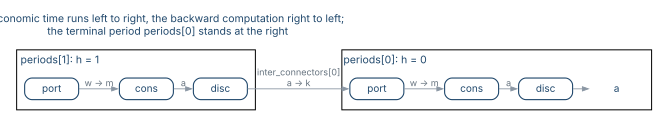

In [20]:
diagram_trellis(two_years)

Each stage occurrence is a copy of its own and records its position in its provenance, the record of where it came from: the earlier year's portfolio stage stands at $h = 1$ under the key `port` and is not the object of the last year's. These separate objects repeat the same mathematical declaration and calibration sources, as [modularity](../../../docs/bellman-calculus/APPX-H-MODULARITY.md) requires. Methods and settings can vary without changing that condition.

In [21]:
two_years["periods"][1]["stages"]["port"].provenance["position"], two_years["periods"][1]["stages"]["port"] is two_years["periods"][0]["stages"]["port"]

(mappingproxy({'h': 1, 'key': 'port'}), False)

A connector that names a field no stage of the period declares is not refused: `accrete` appends the period and keeps the connector as an unresolved endpoint, a diagnostic of the trellis's selection of connections. The next cell appends the period with the inter-period connector `{disc.a: q}`, whose arrival field `q` no stage declares, and prints the trellis's connection report: after its pairs and routes, the line `diagnostic endpoint-unresolved` names the connector's place, the field and the arrival fields the period does have, and the line `source` names the connector.

In [22]:
unresolved = accrete(two_years, beginning, {"disc.a": "q"})
print(connection_report(unresolved))

connection report of the trellis: 7 pairs, 7 routes, 1 diagnostics, 0 rejected inferred candidates (the whole selection: 4 pairs, 3 inferred, 7 routes, 7 certified, 1 diagnostics)
pair periods[0].port.w → periods[0].cons.m: authored (periods[0].connectors[0]); compatible: the continuation set of periods[0].port.w and the arrival set of periods[0].cons.m are one set, ℝ₊₊; basis none (no binding read)
pair periods[1].port.w → periods[1].cons.m: authored (periods[1].connectors[0]); compatible: the continuation set of periods[1].port.w and the arrival set of periods[1].cons.m are one set, ℝ₊₊; basis none (no binding read)
pair periods[2].port.w → periods[2].cons.m: authored (periods[2].connectors[0]); compatible: the continuation set of periods[2].port.w and the arrival set of periods[2].cons.m are one set, ℝ₊₊; basis none (no binding read)
pair periods[1].disc.a → periods[0].port.k: authored (inter_connectors[0]); compatible: the continuation set of periods[1].disc.a and the arrival set o

## Four more years

The same step, repeated, gives a trellis of six years. The next four cells append the third to the sixth year from the end, each to the trellis the cell before it returned.

In [23]:
three_years = accrete(two_years, beginning, {"disc.a": "k"})

The next cell appends the fourth year from the end.

In [24]:
four_years = accrete(three_years, beginning, {"disc.a": "k"})

The next cell appends the fifth.

In [25]:
five_years = accrete(four_years, beginning, {"disc.a": "k"})

The next cell appends the sixth, the household's first year in this model.

In [26]:
six_years = accrete(five_years, beginning, {"disc.a": "k"})

Six periods and five inter-period connectors; the trellis of two years from which it was built still holds two periods. The horizon is the length of the list of periods; this model declares no age field. A model that declares age would also need its supplied terminal age and the backward equations that compute the earlier ages.

In [27]:
len(six_years["periods"]), len(six_years["inter_connectors"]), len(two_years["periods"])

(6, 5, 2)

The next cell draws the last three years; the argument `periods` names them by their indices.

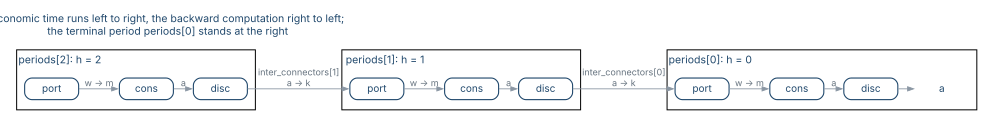

In [28]:
diagram_trellis(six_years, periods=[0, 1, 2])

## Terminal data

The six periods share one calibration. Their positions supply no changing parameter or age. A different calibration defines a different stage operator; it does not define an age recurrence.

The numerical implementation supplies the continuation fields after construction. Here the terminal value is utility from consuming the remaining resources, with its marginal value. The terminal consumption calculation uses zero value after that decision.


In [29]:
terminal = tool.terminal_value(cons, np.linspace(0.01, 20.0, 50))


The complete continuation mapping names the declared value field. No terminal value is added to calibration or the trellis file.


In [30]:
inputs = {"V[>]": terminal}


`check_inputs` checks that mapping before numerical kernels and grids are requested. Its returned conditions remain visible: a Python callable does not establish measurability or its full domain.


In [31]:
disc.check_inputs(inputs)


(Condition(condition='continuation-input', entries=(Identity(kind='field', stage='disc', address=None, perch='cntn', field='V', owner=None, subjects=(), occurrence=None, mark=None), Named(name='ℝ'), Identity(kind='field', stage='disc', address=None, perch='cntn', field='a', owner=None, subjects=(), occurrence=None, mark=None)), status='required', evidence=(), explanation='The representing function for V[>] must be measurable on its declared domain, depend only on (a) in that order, and take values in ℝ.'),)

## The same trellis from its recipe

The six years are also written as two files, the ones the next lesson solves: the recipe, which names the trellis file and, for each stage, its stage file, its calibration and settings files and its addition; and the trellis file, which writes the period once, with `repeat: 6`, and one inter-period connector standing for every pair of consecutive years.

In [32]:
print(open("applications/cons-port/declaration/spec.port-cons.yml").read())
print(open("applications/cons-port/declaration/trellis.port-cons.yml").read())

# The recipe of the demonstration in the order portfolio first: the trellis file and each stage's file, by
# their paths from this folder, and for each stage the sources of its calibration, settings and methods, the
# methods the addition beside the stage file. One calibration serves the three stages; each binds the parameters
# it declares.
trellis: trellis.port-cons.yml
stages:
  cons: {stage: stages/cons/cons.bl, calibration: {all: [calibration/portfolio]}, settings: {all: [settings/cons_wide]}, methods: {all: [stages/cons/methods.bl]}}
  disc: {stage: stages/disc/disc.bl, calibration: {all: [calibration/portfolio]}, methods: {all: [stages/disc/methods.bl]}}
  port: {stage: stages/port/port.bl, calibration: {all: [calibration/portfolio]}, settings: {all: [settings/port_wide]}, methods: {all: [stages/port/methods.bl]}}

!trellis
name: port_cons
# Portfolio first, the returns drawn at the beginning of the period: the share is chosen on capital,
# consumption follows on the resources t

`load_recipe` reads the recipe and its trellis file into a **syntactic trellis**, the same dictionary with each stage a record of its files. The next cell reads it and names it `syntactic`.

In [33]:
syntactic = load_recipe("applications/cons-port/declaration", "spec.port-cons.yml")

The next cell applies the four trellis verbs in turn, `elaborate_trellis`, `methodize_trellis`, `calibrate_trellis` and `configure_trellis`, each to every stage occurrence, and retains each intermediate trellis. The factory's own call, `assemble_trellis`, binds the calibration before the methods; the two orders give the same trellis.


In [34]:
elaborated = elaborate_trellis(syntactic)
methodized_trellis = methodize_trellis(elaborated, syntactic)
calibrated_trellis = calibrate_trellis(methodized_trellis, syntactic)
from_file = configure_trellis(calibrated_trellis, syntactic)


It holds six periods and five inter-period connectors, each `{disc.a: k}`.

In [35]:
len(from_file["periods"]), from_file["inter_connectors"]

(6,
 [{'disc.a': 'k'},
  {'disc.a': 'k'},
  {'disc.a': 'k'},
  {'disc.a': 'k'},
  {'disc.a': 'k'}])

Each trellis holds six copies of one period: every stage occurrence was constructed from the same stage file and bound from the same files, so comparing the last period, $h = 0$, compares all six. The next cell names the stages of that period in each trellis, `by_file` and `by_hand`.

In [36]:
by_file, by_hand = from_file["periods"][0]["stages"], six_years["periods"][0]["stages"]

For the portfolio stage, the next cell compares by `==` the bindings and the two builders graphs, backward and forward, each by `graph`, the record of its operators and of the wires that join them.

In [37]:
(by_file["port"].bindings == by_hand["port"].bindings,
 by_file["port"].builder.bwd.graph == by_hand["port"].builder.bwd.graph,
 by_file["port"].builder.fwd.graph == by_hand["port"].builder.fwd.graph)

(True, True, True)

The next cell makes the same three comparisons for the consumption stage.

In [38]:
(by_file["cons"].bindings == by_hand["cons"].bindings,
 by_file["cons"].builder.bwd.graph == by_hand["cons"].builder.bwd.graph,
 by_file["cons"].builder.fwd.graph == by_hand["cons"].builder.fwd.graph)

(True, True, True)

The next cell makes them for the discount stage.

In [39]:
(by_file["disc"].bindings == by_hand["disc"].bindings,
 by_file["disc"].builder.bwd.graph == by_hand["disc"].builder.bwd.graph,
 by_file["disc"].builder.fwd.graph == by_hand["disc"].builder.fwd.graph)

(True, True, True)

All nine comparisons hold: the trellis built by hand and the trellis read from its recipe are the same model.

The next lesson of this model, [Solving the two orders](03-solving-the-two-orders.ipynb), solves this trellis and the trellis of the consumption-first order.